In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv("../other/Students Social Media Addiction.csv")
df = pd.DataFrame(data)
df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
0,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6,In Relationship,3,8
1,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8,Single,0,3
2,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5,Complicated,4,9
3,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7,Single,1,4
4,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6,In Relationship,2,7


In [3]:
df = df.drop(['Student_ID','Academic_Level','Country','Most_Used_Platform', 'Affects_Academic_Performance','Relationship_Status'], axis=1)
df.tail()

,Age,Gender,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score,Conflicts_Over_Social_Media,Addicted_Score
700,20,Female,4.7,7.2,7,2,5
701,23,Male,6.8,5.9,4,5,9
702,21,Female,5.6,6.7,6,3,7
703,24,Male,4.3,7.5,8,2,4
704,19,Female,6.2,6.3,5,4,8


In [4]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score,Conflicts_Over_Social_Media,Addicted_Score
count,705.000000,705.000000,705.000000,705.000000,705.000000,705.000000
mean,20.659574,4.918723,6.868936,6.226950,2.849645,6.436879
std,1.399217,1.257395,1.126848,1.105055,0.957968,1.587165
min,18.000000,1.500000,3.800000,4.000000,0.000000,2.000000
25%,19.000000,4.100000,6.000000,5.000000,2.000000,5.000000
50%,21.000000,4.800000,6.900000,6.000000,3.000000,7.000000
75%,22.000000,5.800000,7.700000,7.000000,4.000000,8.000000
max,24.000000,8.500000,9.600000,9.000000,5.000000,9.000000


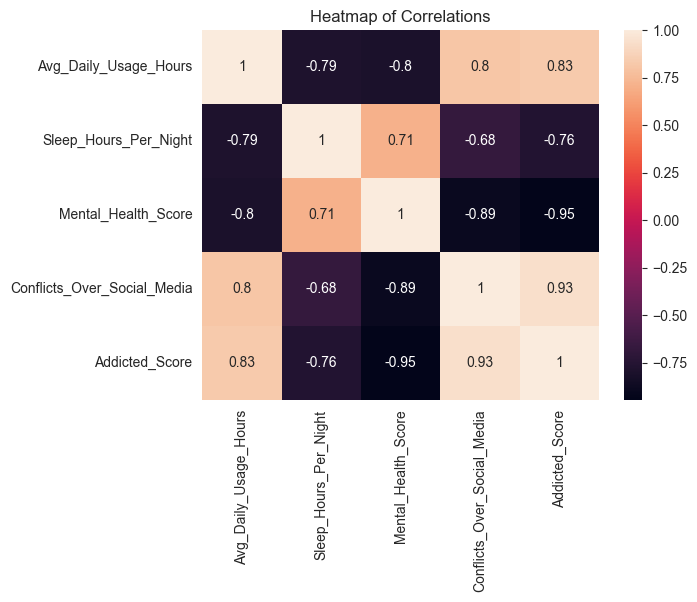

In [5]:
data_corr = df.drop(['Age'], axis=1)
correlation_matrix = data_corr.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True)

plt.title('Heatmap of Correlations')
plt.show()

In [6]:
print("\n-----CORRELATION (top pairs)-----")

corr_unstack = correlation_matrix.unstack().reset_index()
corr_unstack.columns = ['var1', 'var2', 'value']
corr_unstack = corr_unstack[corr_unstack['var1'] != corr_unstack['var2']]
corr_unstack['abs_value'] = corr_unstack['value'].abs()
corr_unstack = corr_unstack.sort_values('abs_value', ascending=False).drop_duplicates(subset=['value'])
display(corr_unstack.head(12))


-----CORRELATION (top pairs)-----


,var1,var2,value,abs_value
22,Addicted_Score,Mental_Health_Score,-0.945051,0.945051
23,Addicted_Score,Conflicts_Over_Social_Media,0.933586,0.933586
17,Conflicts_Over_Social_Media,Mental_Health_Score,-0.893572,0.893572
20,Addicted_Score,Avg_Daily_Usage_Hours,0.832000,0.832000
3,Avg_Daily_Usage_Hours,Conflicts_Over_Social_Media,0.804582,0.804582
10,Mental_Health_Score,Avg_Daily_Usage_Hours,-0.801058,0.801058
1,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,-0.790582,0.790582
21,Addicted_Score,Sleep_Hours_Per_Night,-0.764858,0.764858
7,Sleep_Hours_Per_Night,Mental_Health_Score,0.707439,0.707439
8,Sleep_Hours_Per_Night,Conflicts_Over_Social_Media,-0.677266,0.677266


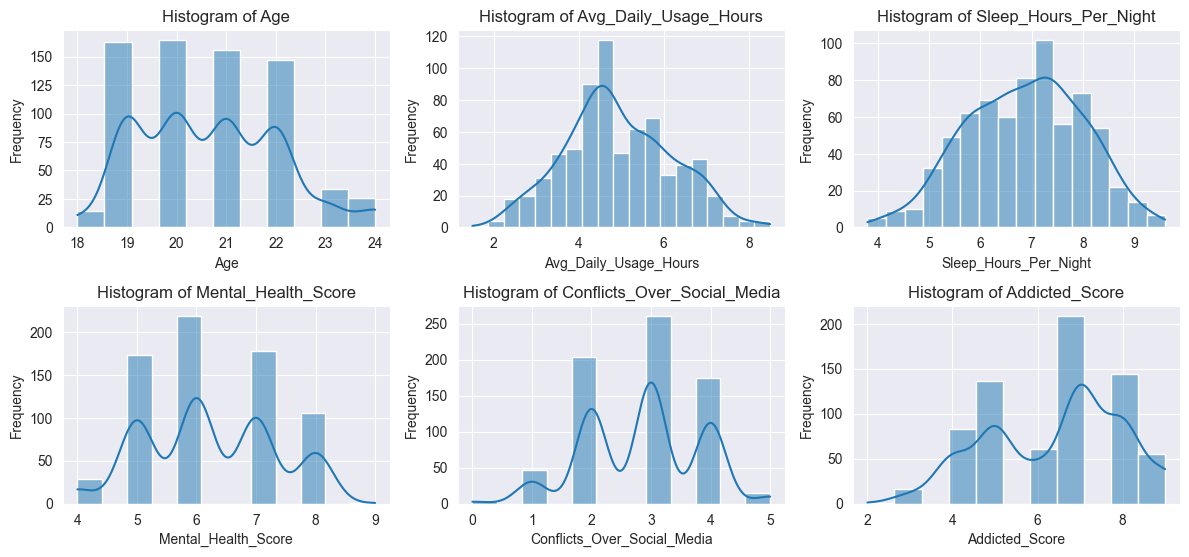

In [7]:
numeric_df = df.drop(['Gender'],axis=1)
plt.figure(figsize= (12,8))

for i, feature in enumerate(numeric_df.columns):
    plt.subplot(3,3,i+1)
    #kde set to true so we can se the curve
    sns.histplot(numeric_df[feature], kde= True)
    plt.title(f'Histogram of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout() #for preventing overlap
plt.show()9